### Assignment 9: CNN Model for Image Classification

#### Load Dataset: 


In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

In [2]:
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

data_dir = tf.keras.utils.get_file(
    "flower_photos",
    origin=dataset_url,
    untar=True
)

print("Dataset location:", data_dir)

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 63s 0us/step
Dataset location: C:\Users\Varshini D\.keras\datasets\flower_photos


### Load images and split the dataset

In [14]:
data_dir = r"C:\Users\Varshini D\.keras\datasets\flower_photos\flower_photos"

IMG_SIZE = (180, 180)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Number of classes: 5


### Normalize images

In [15]:
normalization_layer = tf.keras.layers.Rescaling(1.0 / 255)

train_ds = train_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

val_ds = val_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

### Display sample images

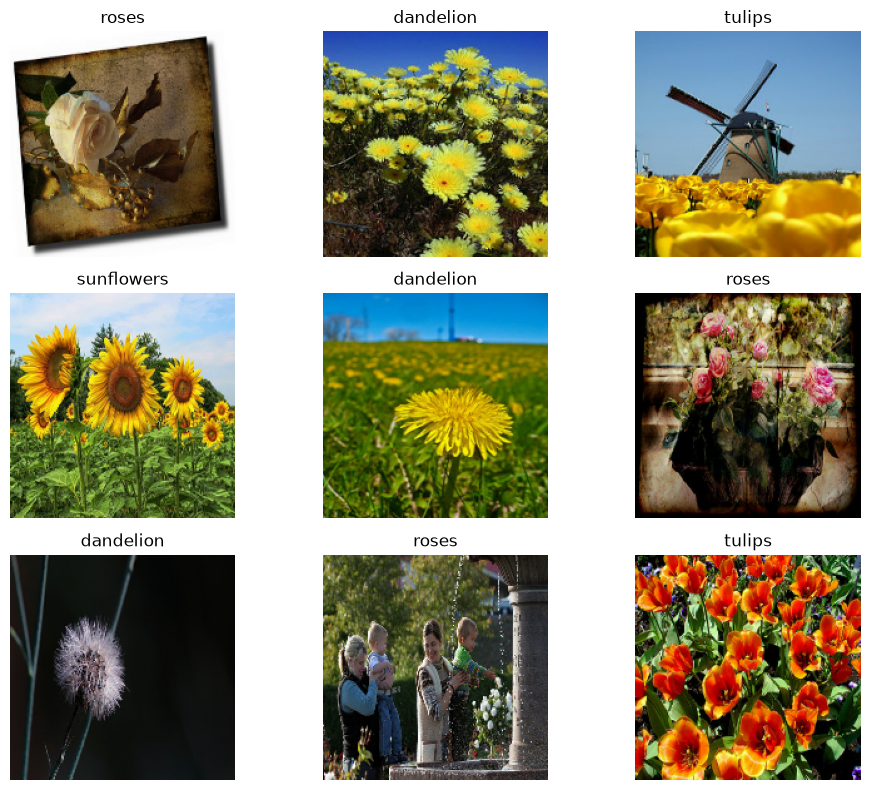

In [16]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy())
    plt.title(class_names[int(labels[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

### Build CNN Model

In [21]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(180, 180, 3)),

    # Convolution + ReLU
    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu"
    ),

    # Pooling
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second convolution block
    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Third convolution block
    tf.keras.layers.Conv2D(
        128, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Fully connected layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),

    # Output: 5 flower categories
    tf.keras.layers.Dense(
        len(class_names),
        activation="softmax"
    )
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,621 (25.36 MB)

 Trainable params: 6,647,621 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

### Compile and Train CNN Model

In [23]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Train the model

In [24]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop]
)


Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 29s 299ms/step - accuracy: 0.3883 - loss: 1.5002 - val_accuracy: 0.5041 - val_loss: 1.1900
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 292ms/step - accuracy: 0.5361 - loss: 1.1222 - val_accuracy: 0.5341 - val_loss: 1.1369
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 291ms/step - accuracy: 0.6284 - loss: 0.9563 - val_accuracy: 0.6240 - val_loss: 0.9844
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 291ms/step - accuracy: 0.6948 - loss: 0.7974 - val_accuracy: 0.6362 - val_loss: 1.0089
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 291ms/step - accuracy: 0.7565 - loss: 0.6413 - val_accuracy: 0.6608 - val_loss: 1.0105
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 294ms/step - accuracy: 0.8532 - loss: 0.4179 - val_accuracy: 0.6471 - val_loss: 1.0835


### Evaluate the Model and Test Predictions

In [25]:
test_loss, test_accuracy = model.evaluate(val_ds)

print("Validation Loss:", test_loss)
print("Validation Accuracy:", test_accuracy)
print(f"Accuracy: {test_accuracy * 100:.2f}%")

23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.6240 - loss: 0.9844
Validation Loss: 0.9844047427177429
Validation Accuracy: 0.6239781975746155
Accuracy: 62.40%


In [33]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

print("Classification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

Classification Report:
              precision    recall  f1-score   support

       daisy       0.71      0.52      0.60       129
   dandelion       0.66      0.59      0.62       176
       roses       0.54      0.56      0.55       120
  sunflowers       0.57      0.95      0.71       152
      tulips       0.71      0.48      0.58       157

    accuracy                           0.62       734
   macro avg       0.64      0.62      0.61       734
weighted avg       0.64      0.62      0.62       734



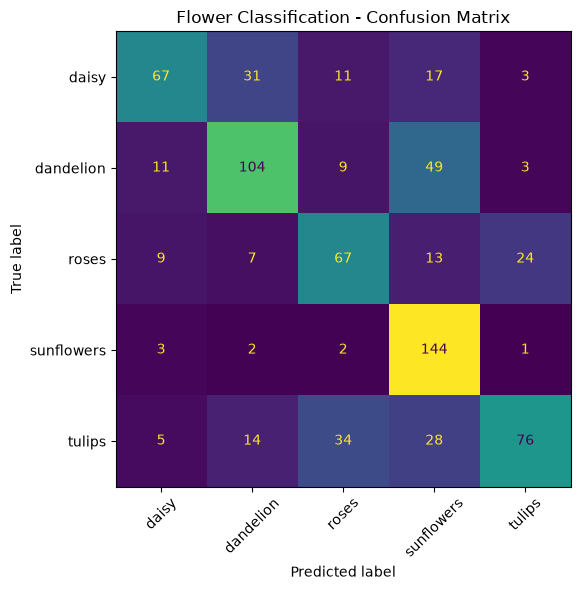

In [34]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)

plt.title("Flower Classification - Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

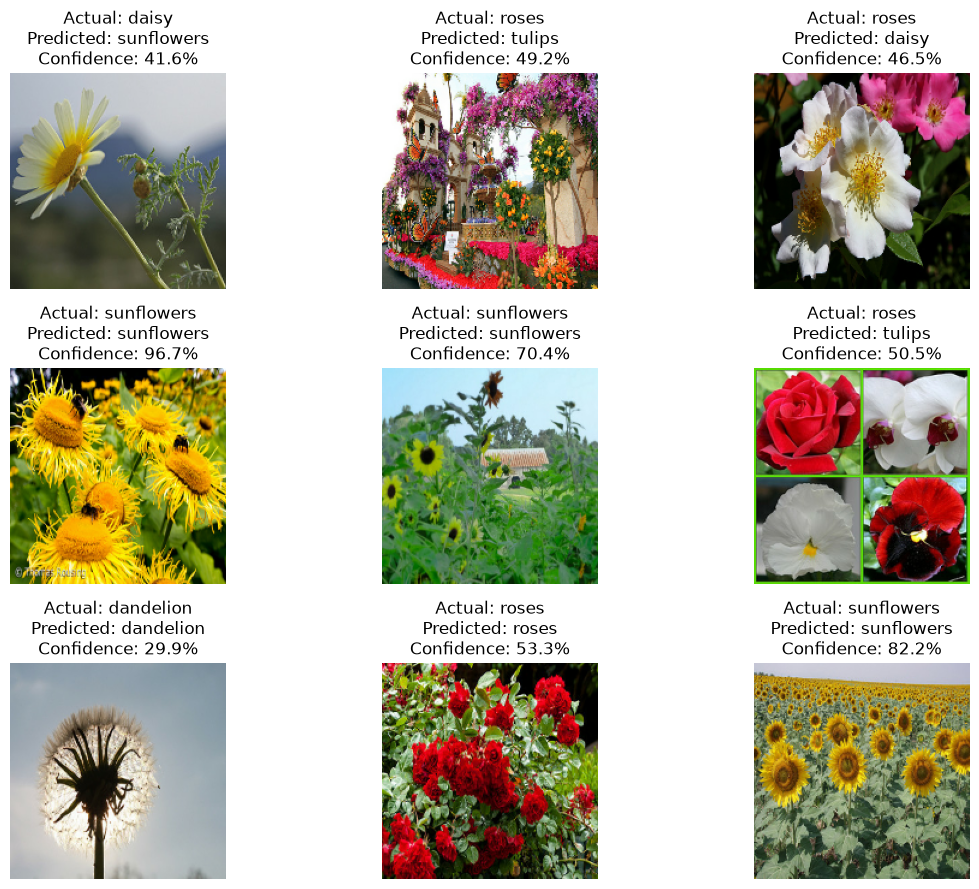

In [35]:
plt.figure(figsize=(12, 9))

for images, labels in val_ds.take(1):

    probabilities = model.predict(images, verbose=0)

    predicted_classes = np.argmax(probabilities, axis=1)
    confidences = np.max(probabilities, axis=1)

    for i in range(min(9, len(images))):

        img = images[i].numpy()

        # Display correctly whether pixel values are 0–1 or 0–255
        if img.max() <= 1.0:
            display_img = img
        else:
            display_img = img.astype("uint8")

        actual = class_names[int(labels[i])]
        predicted = class_names[int(predicted_classes[i])]

        plt.subplot(3, 3, i + 1)
        plt.imshow(display_img)
        plt.title(
            f"Actual: {actual}\n"
            f"Predicted: {predicted}\n"
            f"Confidence: {confidences[i]:.1%}"
        )
        plt.axis("off")

plt.tight_layout()
plt.savefig("sample_predictions.png", dpi=150)
plt.show()

### Accuracy and Loss Graphs

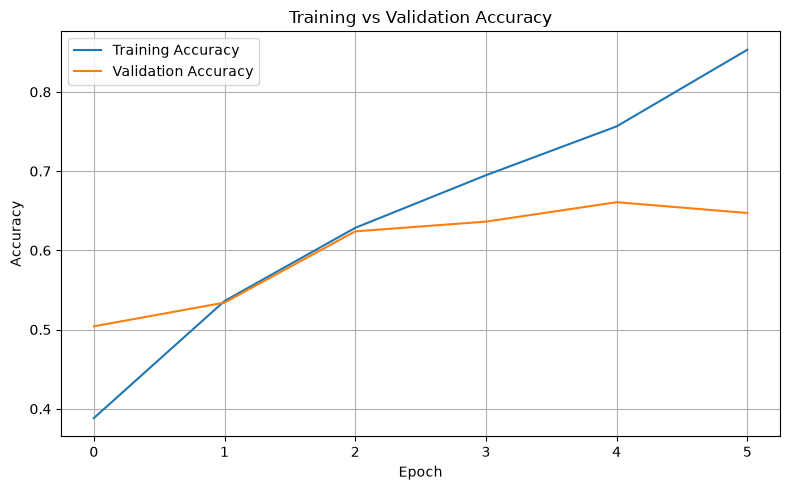

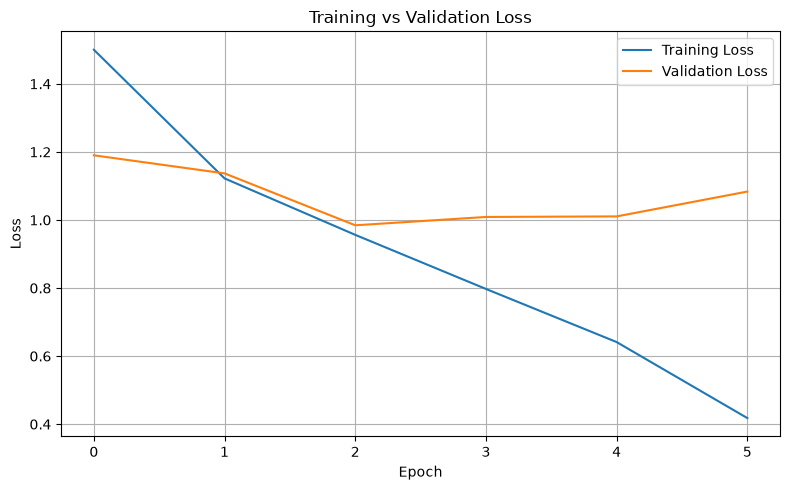

In [36]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("accuracy_curve.png", dpi=150)
plt.show()


# Loss graph
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150)
plt.show()

In [37]:
import numpy as np

train_acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

best_epoch = np.argmax(val_acc)

print("Total epochs completed:", len(train_acc))
print("Best epoch:", best_epoch + 1)
print(f"Best training accuracy: {train_acc[best_epoch]:.2%}")
print(f"Best validation accuracy: {val_acc[best_epoch]:.2%}")
print(f"Training loss at best epoch: {train_loss[best_epoch]:.4f}")
print(f"Validation loss at best epoch: {val_loss[best_epoch]:.4f}")

Total epochs completed: 6
Best epoch: 5
Best training accuracy: 75.65%
Best validation accuracy: 66.08%
Training loss at best epoch: 0.6413
Validation loss at best epoch: 1.0105
